# Fourier interpolation of aerial images: CD at the resist threshold and the Gibbs phenomenon

The constant threshold resist of the lithography notebooks prints wherever
the dose times the aerial image exceeds a threshold; the **CD** is the
distance of the two threshold crossings around a feature. A simulator (or an
aerial image measurement) delivers the image on a grid, and the crossings
fall between the grid points. How fine must the grid be, and how should one
interpolate?

The answer comes from the optics. The lens passes plane waves up to
$\sin\theta = \mathrm{NA}$ only; the intensity, a sum of products of two such
waves, holds the spatial frequencies up to

$$ f_c = \frac{2\,\mathrm{NA}}{\lambda} $$

and nothing above, for any source, polarization, focus, aberration or film
stack (the transverse frequencies are conserved through the resist).
**The aerial image is band limited**, so by the sampling theorem a grid with
$\Delta x \le \lambda/(4\,\mathrm{NA})$ (36 nm for ArF immersion at NA 1.35)
carries the whole image, and the trigonometric (Fourier) interpolation of
the samples *is* the image, between the grid points too. Linear or spline
interpolation of the same samples is not.

The resist pattern after the threshold, the binary mask and anything else
with sharp edges is *not* band limited. Fourier interpolation (and the
projection lens itself) then rings next to every edge: the
**Gibbs phenomenon**. Spectral windows such as Lanczos' sigma factors trade
the ringing for a broader edge.

`pyoptics.interpolator` provides the tools:

| function | what it does |
|---|---|
| `trig_interpolate(f, x, x_out, axis)` | 1D trigonometric interpolation at any points |
| `trig_interpolate_2d(f, x, y, x_out, y_out)` | images and complex fields on any grid or at scattered points |
| `fourier_upsample(f, factor)` | refinement by zero padding the spectrum (FFT speed) |
| `TrigInterpolator(image, x, y, f_cutoff)` | an image with a frequency cutoff (e.g. $2\,\mathrm{NA}/\lambda$), callable |
| `level_crossings(x, f, level)` | exact level crossings of the interpolant of a periodic cut |
| `smoothing_window(nu, kind)` | windows against Gibbs: `"lanczos"` (sigma factors), `"fejer"`, `"hann"`, `"gaussian"` |

and `litho.metrics.threshold_cd(..., interpolation="fourier")` measures the
CD on the trigonometric interpolant of one period of a cut.

Contents:

1. The spectrum of an aerial image ends at $2\,\mathrm{NA}/\lambda$
2. CD from a coarse grid: linear, spline and Fourier interpolation
3. Below the Nyquist limit: aliasing
4. Two-dimensional images: contact holes
5. The Gibbs phenomenon: masks, the lens, and why one thresholds last

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

from pyoptics.interpolator import (fourier_upsample, level_crossings, smoothing_window,
                                   trig_interpolate, trig_interpolate_2d, upsampled_grid)
from pyoptics.litho import Illumination, LithoSimulation, MaskLayout, Projector, ThinMask, metrics

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

wl, n_w, NA = 193.0, 1.437, 1.35
water = Projector(NA, wl, n_w)
f_c = 2*NA/wl          # band limit of the intensity [1/nm]
dx_nyq = wl/(4*NA)     # largest grid spacing that carries the image
print(f"f_c = 2 NA/lambda = {1e3*f_c:.2f} per um, grid spacing <= lambda/(4 NA) = {dx_nyq:.1f} nm")

THRESHOLD = 0.3
cases = {
    "45 nm L/S, pitch 90": LithoSimulation(
        MaskLayout.lines_spaces(90.0, 45.0), ThinMask.binary(),
        Illumination.dipole_for_pitch(90.0, wl, NA, polarization="y"), water),
    "45 nm trench, pitch 300": LithoSimulation(
        MaskLayout.lines_spaces(300.0, 45.0, tone="dark"), ThinMask.att_psm(0.06),
        Illumination.annular(0.9, 0.6, polarization="TE"), water),
    "45 nm iso line, pitch 900": LithoSimulation(
        MaskLayout.iso_line(45.0, pitch=900.0), ThinMask.att_psm(0.06),
        Illumination.annular(0.9, 0.6, polarization="TE"), water),
}
dose = {name: sim.dose_to_size(threshold=THRESHOLD) for name, sim in cases.items()}


def periodic_cut(sim, N):
    # N samples of one period, centred on the first feature, end point excluded
    p = sim.layout.pitch_x
    c = sim.layout.features[0][0]
    u = c - p/2 + p*np.arange(N)/N
    return u, np.ravel(sim.image(u, None))


def fourier_cd(sim, u, I, D):
    return metrics.threshold_cd(u, D*I, THRESHOLD, sim.layout.features[0][0],
                                sim.layout.feature_is_bright, interpolation="fourier")


def fine_cd(sim, u_fine, I_fine, D):
    # CD of an interpolant evaluated on a fine grid (linear crossings there)
    return metrics.threshold_cd(u_fine, D*I_fine, THRESHOLD, sim.layout.features[0][0],
                                sim.layout.feature_is_bright)

f_c = 2 NA/lambda = 13.99 per um, grid spacing <= lambda/(4 NA) = 35.7 nm


## 1. The spectrum of an aerial image ends at $2\,\mathrm{NA}/\lambda$

A periodic image of pitch $p$ is a Fourier series with the frequencies
$m/p$. Behind the lens only the harmonics with $|m|/p \le 2\,\mathrm{NA}/\lambda$
survive, $M = \lfloor 2\,\mathrm{NA}\,p/\lambda \rfloor$ of them on each side;
$N = 2M + 1$ samples per pitch determine them all. The 45 nm lines and
spaces at pitch 90 nm ($k_1 = 0.31$) have $M = 1$: the image is *exactly*
$a + b\cos(2\pi x/p)$, three samples per pitch fix it. The isolated line
(pitch 900 nm) needs 25.

Below: the Fourier coefficients of the three images (from 2048 samples per
period, i.e. far finer than needed): they drop to the roundoff level at
$f_c$ (dashed). The source can leave out harmonics below $f_c$ too: harmonic
$m$ needs two orders $\Delta m = m$ apart inside the pupil for some source
point. For the trench at pitch 300 nm, $M = 4$, but the fourth harmonic would
need source points at $\sigma \approx 0.48$ or $0.95$, outside the annulus
0.6–0.9, so its image has three harmonics only. $2M + 1$ samples are the
safe rule, independent of the source.

case                           dose   M  N_min  p/N_min [nm]  harmonics present
45 nm L/S, pitch 90           0.847   1      3          30.0                  1
45 nm trench, pitch 300       2.992   4      9          33.3                  3
45 nm iso line, pitch 900     0.761  12     25          36.0                 12


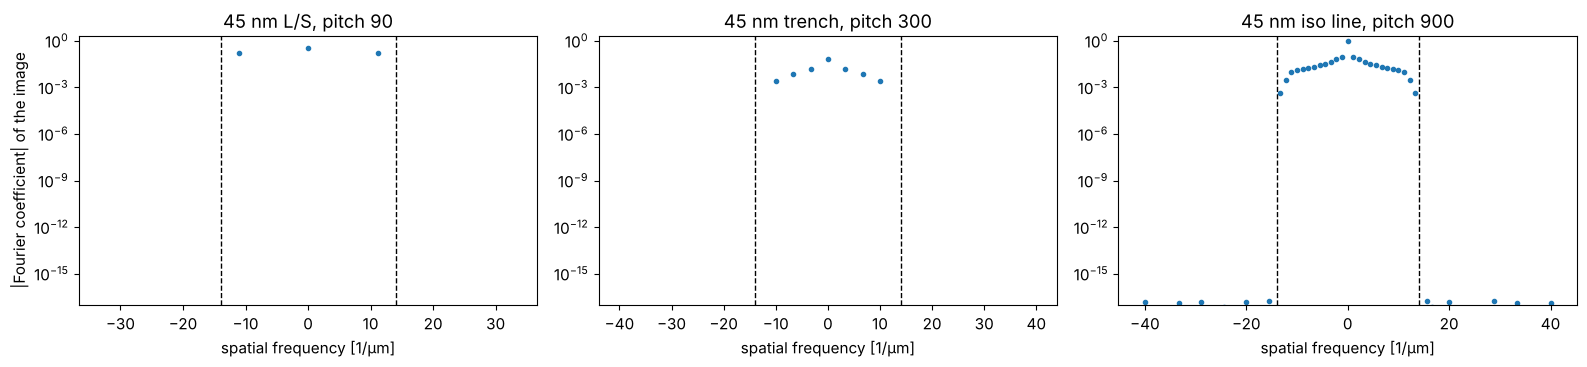

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
print(f"{'case':28s} {'dose':>6s} {'M':>3s} {'N_min':>6s} {'p/N_min [nm]':>13s} {'harmonics present':>18s}")
for ax, (name, sim) in zip(axes, cases.items()):
    p = sim.layout.pitch_x
    u, I = periodic_cut(sim, 2048)
    c = np.fft.fftshift(np.fft.fft(I))/len(I)
    m = np.arange(-1024, 1024)
    keep = np.abs(m/p) < 3*f_c
    ax.semilogy(1e3*m[keep]/p, np.abs(c[keep]) + 1e-18, "o", ms=3)
    for s in (-1, 1):
        ax.axvline(1e3*s*f_c, color="k", ls="--", lw=1)
    ax.set_ylim(1e-17, 2)
    ax.set_xlabel("spatial frequency [1/µm]"); ax.set_title(name)
    M = int(np.floor(p*f_c))
    present = int(np.max(np.abs(m[np.abs(c) > 1e-12])))
    print(f"{name:28s} {dose[name]:6.3f} {M:3d} {2*M + 1:6d} {p/(2*M + 1):13.1f} {present:18d}")
axes[0].set_ylabel("|Fourier coefficient| of the image")
fig.tight_layout()

## 2. CD from a coarse grid: linear, spline and Fourier interpolation

The three images on a grid of about 30 nm (3, 10 and 30 samples per pitch),
at the dose to size. The exact image (grey) is the direct sum of the
diffraction orders on a fine grid. Linear interpolation (orange) cuts the
corners of the image, so its threshold crossings are off by several nm; the
trigonometric interpolant (blue) runs through the exact image.

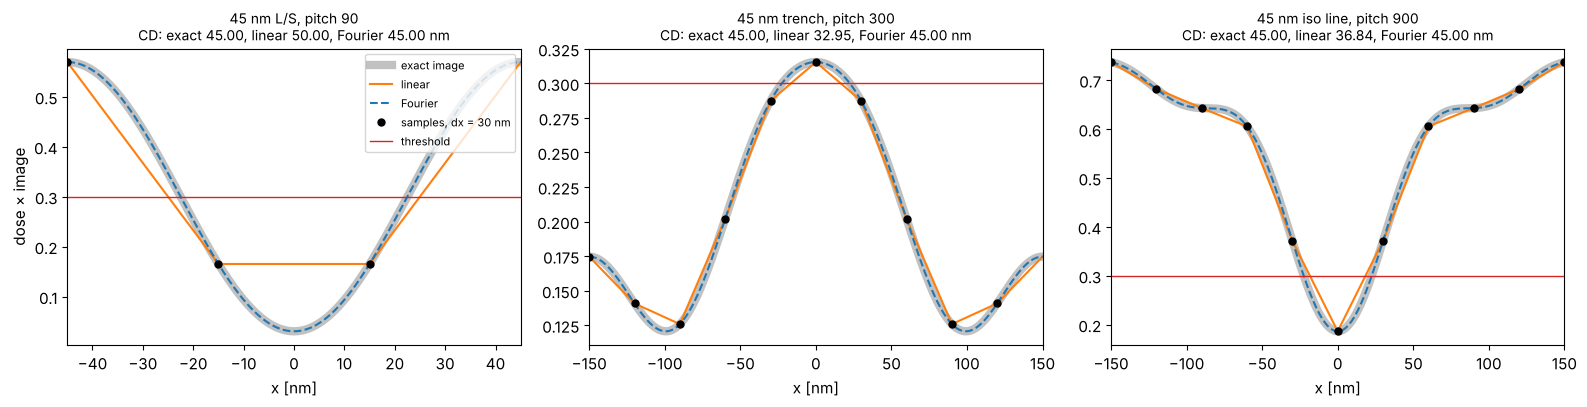

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, sim) in zip(axes, cases.items()):
    p = sim.layout.pitch_x
    D = dose[name]
    N = int(np.ceil(p/30.0))
    u, I = periodic_cut(sim, N)
    span = min(p/2, 150.0)
    uf = np.linspace(-span, span, 1201)
    I_exact = np.ravel(sim.image(uf, None))
    I_lin = np.interp(uf, u, I, period=p)
    I_four = trig_interpolate(I, u, uf)
    ax.plot(uf, D*I_exact, color="0.6", lw=6, alpha=0.6, label="exact image")
    ax.plot(uf, D*I_lin, color="C1", lw=1.5, label="linear")
    ax.plot(uf, D*I_four, color="C0", lw=1.5, ls="--", label="Fourier")
    inside = np.abs(u) <= span
    ax.plot(u[inside], D*I[inside], "ko", ms=5, label=f"samples, dx = {p/N:.0f} nm")
    ax.axhline(THRESHOLD, color="C3", lw=1, label="threshold")
    cd_ref = fourier_cd(sim, *periodic_cut(sim, 4*N), D)
    uu = np.linspace(-p/2, p/2, 20001)
    cd_lin = fine_cd(sim, uu, np.interp(uu, u, I, period=p), D)
    cd_four = fourier_cd(sim, u, I, D)
    ax.set_title(f"{name}\nCD: exact {cd_ref:.2f}, linear {cd_lin:.2f}, Fourier {cd_four:.2f} nm",
                 fontsize=10)
    ax.set_xlabel("x [nm]"); ax.set_xlim(-span, span)
axes[0].set_ylabel("dose × image"); axes[0].legend(fontsize=8, loc="upper right")
fig.tight_layout()

How fast does each interpolation converge? Below the CD error against the
grid spacing for the three features (at 1.07 times the dose to size): linear interpolation (error
$\propto \Delta x^2$, the curvature of the image at the edge), a periodic
cubic spline ($\propto \Delta x^4$) and Fourier interpolation, which is exact
(roundoff) as soon as $\Delta x < p/(2M + 1)$, at the latest at
$\lambda/(4\,\mathrm{NA})$ (dotted). For 0.1 nm accuracy the linear
interpolation needs a grid of 2–4 nm, i.e. 20 to 200 times more image
points than the Fourier interpolation (and the direct sum of the orders
costs time per point; `LithoSimulation.cd()` uses 401 points per period for
that reason).

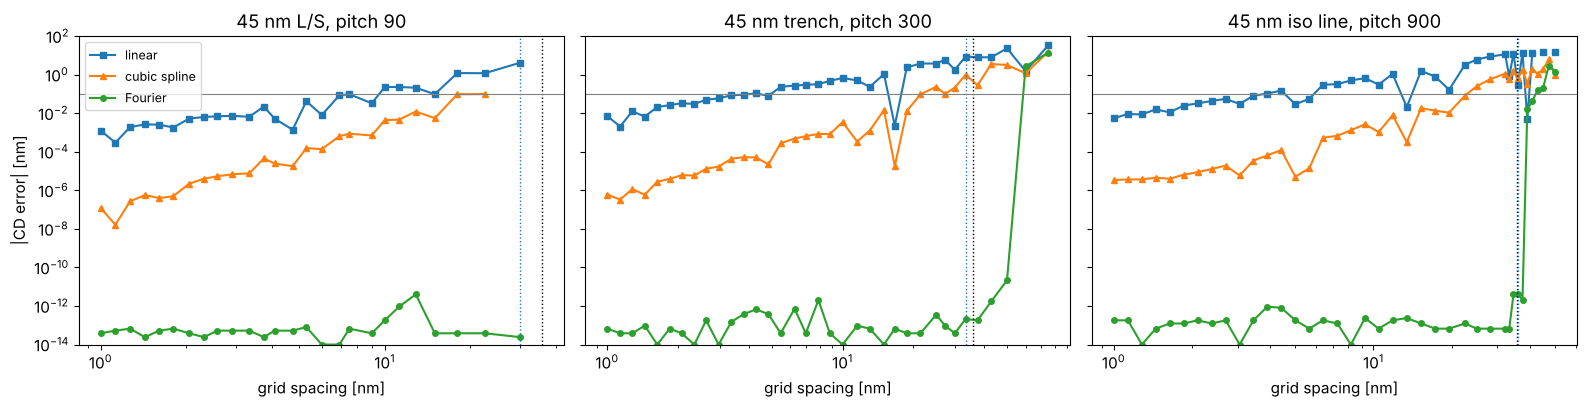

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, (name, sim) in zip(axes, cases.items()):
    p = sim.layout.pitch_x
    D = 1.07*dose[name]  # off the dose to size, so that no grid has a sample right on an edge
    M = int(np.floor(p*f_c))
    cd_ref = fourier_cd(sim, *periodic_cut(sim, 8*M + 8), D)
    Ns = np.unique(np.geomspace(2*M + 1 if M > 2 else 3, p/1.0, 30).astype(int))
    Ns = np.unique(np.concatenate([Ns, np.arange(max(3, 2*M - 6), 2*M + 4)]))
    uu = np.linspace(-p/2, p/2, 40001)
    err = {"linear": [], "cubic spline": [], "Fourier": []}
    for N in Ns:
        u, I = periodic_cut(sim, N)
        err["linear"].append(fine_cd(sim, uu, np.interp(uu, u, I, period=p), D) - cd_ref)
        if N >= 4:
            spl = CubicSpline(np.append(u, u[0] + p), np.append(I, I[0]), bc_type="periodic")
            err["cubic spline"].append(fine_cd(sim, uu, spl(uu), D) - cd_ref)
        else:
            err["cubic spline"].append(np.nan)
        err["Fourier"].append(fourier_cd(sim, u, I, D) - cd_ref)
    for (label, e), mk in zip(err.items(), ("s", "^", "o")):
        ax.loglog(p/Ns, np.abs(e) + 1e-14, mk + "-", ms=4, label=label)
    ax.axvline(dx_nyq, color="k", ls=":", lw=1)
    ax.axvline(p/(2*M + 1), color="C0", ls=":", lw=1)
    ax.axhline(0.1, color="0.5", lw=0.8)
    ax.set_xlabel("grid spacing [nm]"); ax.set_title(name)
    ax.set_ylim(1e-14, 1e2)
axes[0].set_ylabel("|CD error| [nm]")
axes[0].legend(fontsize=9)
fig.tight_layout()

## 3. Below the Nyquist limit: aliasing

With $\Delta x > p/(2M + 1)$ some harmonics of the image are missing from
the grid; they fold onto lower frequencies (aliasing), and the
trigonometric interpolant is a *different* band-limited function through
the same samples. How wrong it is depends on the amplitude of the missing
harmonics: for the trench at pitch 300 nm (third harmonic 4 % of the mean)
the CD from 4 or 5 samples is off by several nm. For the isolated line the
harmonics near the cutoff are weak (see section 1): 22 samples miss the
CD by 0.04 nm only, but it is no longer exact. (24 samples still are: for
even $N$ the Nyquist sample carries a cosine about the feature centre, and
the symmetric image has no sine part.) No interpolation can repair an
undersampled image: the grid must be chosen from the optics,
$\Delta x \le \lambda/(4\,\mathrm{NA})$, not from the feature size.

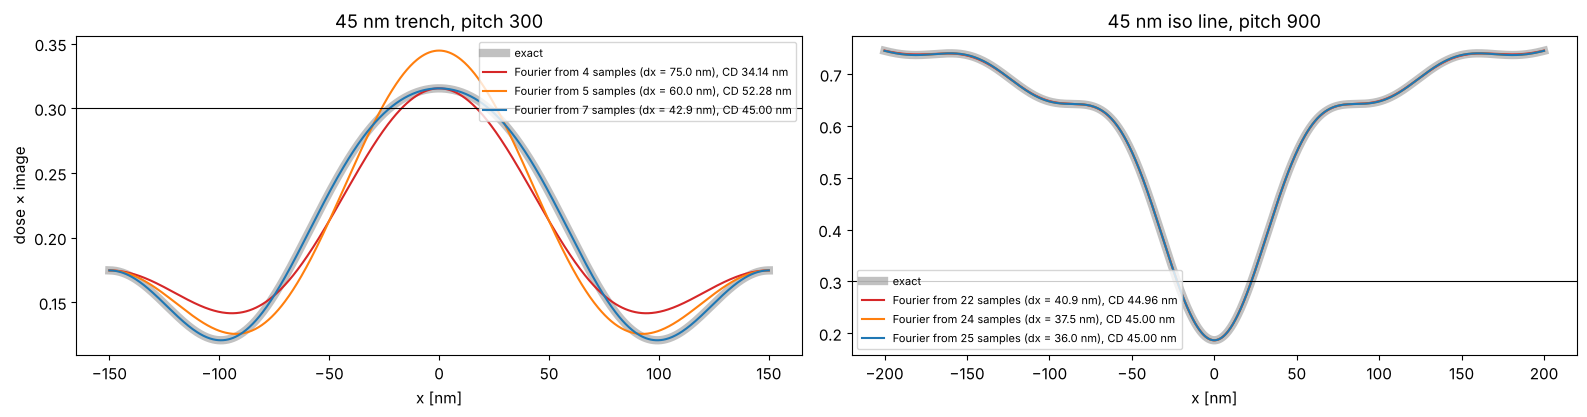

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.3))
for ax, (name, Ns, span) in zip(axes, (("45 nm trench, pitch 300", (4, 5, 7), 150),
                                       ("45 nm iso line, pitch 900", (22, 24, 25), 200))):
    sim, D = cases[name], dose[name]
    p = sim.layout.pitch_x
    uf = np.linspace(-span, span, 801)
    ax.plot(uf, D*np.ravel(sim.image(uf, None)), color="0.6", lw=6, alpha=0.6, label="exact")
    for N, c in zip(Ns, ("C3", "C1", "C0")):
        u, I = periodic_cut(sim, N)
        ax.plot(uf, D*trig_interpolate(I, u, uf), color=c, lw=1.5,
                label=f"Fourier from {N} samples (dx = {p/N:.1f} nm), CD {fourier_cd(sim, u, I, D):.2f} nm")
    ax.axhline(THRESHOLD, color="k", lw=0.8)
    ax.set_xlabel("x [nm]"); ax.legend(fontsize=8)
    ax.set_title(name)
axes[0].set_ylabel("dose × image")
fig.tight_layout()

## 4. Two-dimensional images: contact holes

In two dimensions the image spectrum fills the disc
$f_x^2 + f_y^2 \le f_c^2$; a rectangular grid with
$\Delta x, \Delta y \le \lambda/(4\,\mathrm{NA})$ holds it.
`fourier_upsample()` refines the grid by zero padding the spectrum, at FFT
speed; `trig_interpolate_2d()` evaluates the same trigonometric polynomial
on any grid or at scattered points (e.g. along edge normals for OPC).

Left: the spectrum of a staggered contact array (60 nm holes, 6 % att. PSM,
annular TE), all orders inside the circle $f_c$. Middle: the threshold
contour from the direct sum on a 1 nm grid (exact), from 8 × 12 samples per
cell (20 nm) Fourier upsampled ×16, and from the same coarse samples drawn
with `matplotlib.contour` (linear interpolation in each grid cell).
Right: the CD of the holes in $x$ and $y$ against the grid spacing, from
cuts through the hole centre (which need not lie on the grid: the rows or
columns are first interpolated to it, bilinear against Fourier). The holes
print elliptical: the dose sizes them to 60 nm in $x$.

coarse grid 8 x 12 (dx = 20 nm, dy = 20 nm), upsampled to 128 x 192 in 0.7 ms
max |upsampled - exact| on the fine grid: 6.9e-17 (image max 0.07)


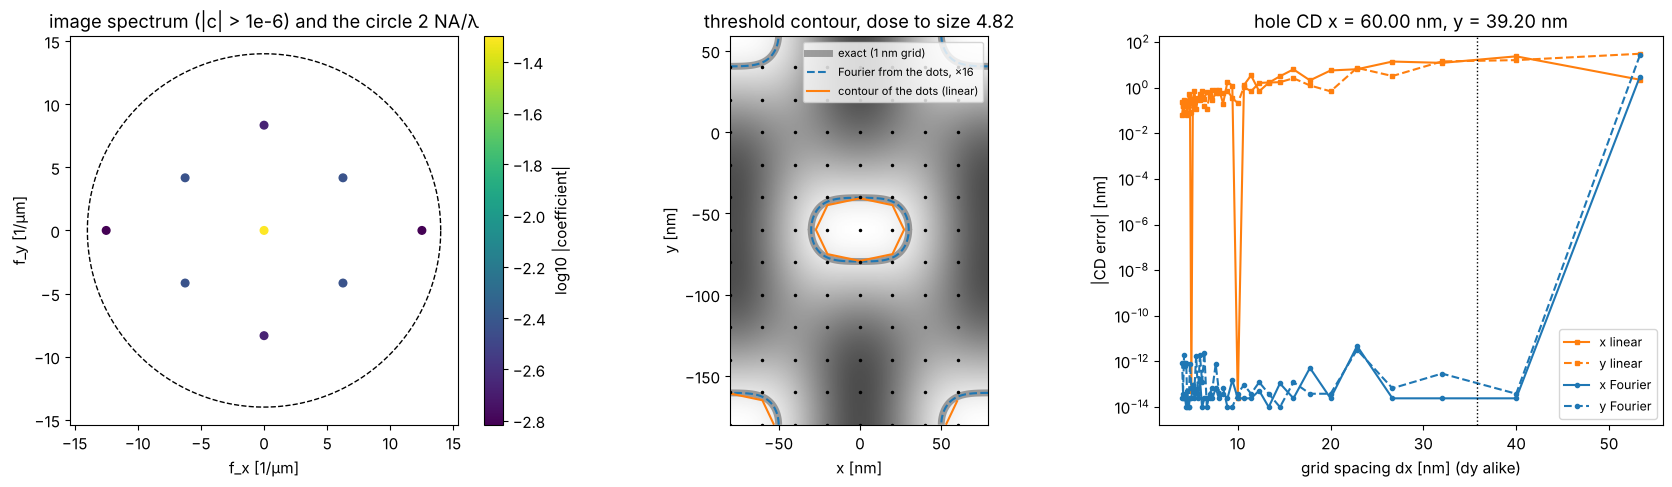

In [6]:
sim2 = LithoSimulation(MaskLayout.staggered_contacts(160.0, 120.0, 60.0), ThinMask.att_psm(0.06),
                       Illumination.annular(0.9, 0.6, polarization="TE"), water)
D2 = sim2.dose_to_size(threshold=THRESHOLD)
px, py = sim2.layout.pitch_x, sim2.layout.pitch_y
x0, y0 = sim2.layout.features[0][:2]


def cell(N, P, c):
    return c - P/2 + P*np.arange(N)/N


def grid_image(Nx, Ny):
    x, y = cell(Nx, px, x0), cell(Ny, py, y0)
    return x, y, sim2.image(x, y)


# exact reference: direct sum on a fine grid
xf, yf, If = grid_image(160, 240)
# coarse grid and Fourier upsampling
Nx, Ny = 8, 12
xc, yc, Ic = grid_image(Nx, Ny)
t = time.perf_counter()
Iu = fourier_upsample(Ic, 16)
t_up = time.perf_counter() - t
xu, yu = upsampled_grid(xc, 16), upsampled_grid(yc, 16)
print(f"coarse grid {Nx} x {Ny} (dx = {px/Nx:.0f} nm, dy = {py/Ny:.0f} nm), upsampled to "
      f"{Iu.shape[1]} x {Iu.shape[0]} in {1e3*t_up:.1f} ms")
print(f"max |upsampled - exact| on the fine grid: "
      f"{np.abs(trig_interpolate_2d(Ic, xc, yc, xf, yf) - If).max():.1e} (image max {If.max():.2f})")


def centre_cuts(x, y, I, interpolation):
    # cuts through the hole centre (x0, y0), which need not be on the grid:
    # interpolate the rows (columns) of the grid to y0 (x0), Fourier or linear
    if interpolation == "fourier":
        return trig_interpolate(I, y, y0, axis=0), trig_interpolate(I, x, x0, axis=1)
    row = np.array([np.interp(y0, y, col, period=py) for col in I.T])
    col = np.array([np.interp(x0, x, r, period=px) for r in I])
    return row, col


def hole_cd(x, y, I, interpolation):
    # CD of the hole at (x0, y0) in x and y
    row, col = centre_cuts(x, y, I, interpolation)
    if interpolation == "fourier":
        return (metrics.threshold_cd(x, D2*row, THRESHOLD, x0, True, "fourier"),
                metrics.threshold_cd(y, D2*col, THRESHOLD, y0, True, "fourier"))
    out = []
    for u, v, P, c in ((x, row, px, x0), (y, col, py, y0)):
        uu = np.linspace(c - P/2, c + P/2, 20001)
        out.append(metrics.threshold_cd(uu, D2*np.interp(uu, u, v, period=P), THRESHOLD, c, True))
    return tuple(out)


fig, axes = plt.subplots(1, 3, figsize=(17, 5))
F = np.fft.fftshift(np.fft.fft2(If))/If.size
fx = np.fft.fftshift(np.fft.fftfreq(len(xf), xf[1] - xf[0]))
fy = np.fft.fftshift(np.fft.fftfreq(len(yf), yf[1] - yf[0]))
FX, FY = np.meshgrid(fx, fy)
sel = np.abs(F) > 1e-6
sc = axes[0].scatter(1e3*FX[sel], 1e3*FY[sel], c=np.log10(np.abs(F[sel])), s=30, cmap="viridis")
plt.colorbar(sc, ax=axes[0], label="log10 |coefficient|")
th = np.linspace(0, 2*np.pi, 200)
axes[0].plot(1e3*f_c*np.cos(th), 1e3*f_c*np.sin(th), "k--", lw=1)
axes[0].set_aspect("equal"); axes[0].set_xlabel("f_x [1/µm]"); axes[0].set_ylabel("f_y [1/µm]")
axes[0].set_title("image spectrum (|c| > 1e-6) and the circle 2 NA/λ")

ax = axes[1]
ext = (xf[0], xf[-1], yf[0], yf[-1])
ax.imshow(D2*If, extent=ext, origin="lower", cmap="gray", alpha=0.7)
ax.contour(xf, yf, D2*If, [THRESHOLD], colors="0.3", linewidths=5, alpha=0.5)
ax.contour(xu, yu, D2*Iu, [THRESHOLD], colors="C0", linewidths=1.5, linestyles="--")
ax.contour(xc, yc, D2*Ic, [THRESHOLD], colors="C1", linewidths=1.5)
Xc, Yc = np.meshgrid(xc, yc)
ax.plot(Xc, Yc, "k.", ms=3)
ax.plot([], [], color="0.3", lw=5, alpha=0.5, label="exact (1 nm grid)")
ax.plot([], [], "C0--", label="Fourier from the dots, ×16")
ax.plot([], [], "C1", label="contour of the dots (linear)")
ax.legend(fontsize=8, loc="upper right"); ax.set_xlabel("x [nm]"); ax.set_ylabel("y [nm]")
ax.set_title(f"threshold contour, dose to size {D2:.2f}")

ref = hole_cd(*grid_image(48, 72), "fourier")
Ns = np.arange(3, 41)
rows = {"x linear": [], "y linear": [], "x Fourier": [], "y Fourier": []}
for N in Ns:
    Nxx, Nyy = N, int(round(N*py/px))
    x, y, I = grid_image(Nxx, Nyy)
    lin = hole_cd(x, y, I, "linear")
    four = hole_cd(x, y, I, "fourier")
    rows["x linear"].append(lin[0] - ref[0]); rows["y linear"].append(lin[1] - ref[1])
    rows["x Fourier"].append(four[0] - ref[0]); rows["y Fourier"].append(four[1] - ref[1])
for (label, e), st in zip(rows.items(), ("s-", "s--", "o-", "o--")):
    axes[2].semilogy(px/Ns, np.abs(e) + 1e-14, st, ms=3, label=label, color="C1" if "lin" in label else "C0")
axes[2].axvline(dx_nyq, color="k", ls=":", lw=1)
axes[2].set_xlabel("grid spacing dx [nm] (dy alike)"); axes[2].set_ylabel("|CD error| [nm]")
axes[2].set_title(f"hole CD x = {ref[0]:.2f} nm, y = {ref[1]:.2f} nm"); axes[2].legend(fontsize=9)
fig.tight_layout()

The contour that `matplotlib` draws through the coarse samples has kinks at
every grid line and a CD error of several nm; the upsampled image gives the
exact contour from 96 samples per cell. Above 36 nm (dotted) the grid
misses orders and both fail.

## 5. The Gibbs phenomenon: masks, the lens, and why one thresholds last

### 5a. Interpolating what is not band limited

A binary mask, a resist pattern or any image with sharp edges has
harmonics up to infinity. Its trigonometric interpolant still passes
through the samples, but between them it overshoots next to each edge by
about 14 % of the jump (9 % for the truncated Fourier series of a step),
however fine the grid; the ripples run through the whole period. Spectral
windows $w(f/f_\mathrm{cut})$ that fall to zero at the cutoff suppress the
ringing and broaden the edge (the result then no longer interpolates the
samples):

- **Lanczos sigma factors** $w = \mathrm{sinc}(\nu)$ average the series over
  one period of its highest harmonic; squared, twice,
- **Fejér** $w = 1 - |\nu|$ (Cesàro mean): a positive kernel, no overshoot,
- **Hann** $w = \cos^2(\pi\nu/2)$, and a **Gaussian**, the transfer function of
  a Gaussian blur.

Below: the transmission of 120 nm lines at pitch 480 nm sampled on an 8 nm
grid (a pixelated mask as used in inverse lithography) and Fourier upsampled
×16 with each window, and the transmission of one contact hole of a pixel
map in 2D.

window        overshoot  10-90 % rise [nm]
none              14.8 %                2.5
lanczos            2.1 %                5.4
lanczos²           0.4 %                7.8
hann               1.0 %                6.8
fejer             -0.4 %                7.1
gaussian           0.2 %                7.1


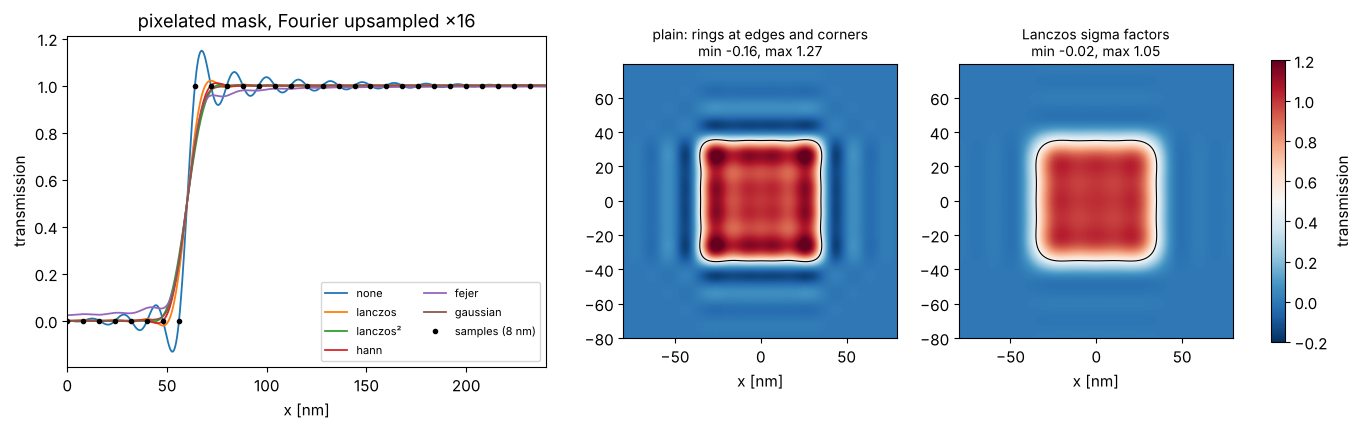

In [7]:
p_m, N_m = 480.0, 60
xm = -p_m/2 + p_m*np.arange(N_m)/N_m
t_mask = (np.abs(xm) >= 60.0).astype(float)  # clear field, dark 120 nm line
xu_m = upsampled_grid(xm, 16)
windows = [("none", 1), ("lanczos", 1), ("lanczos", 2), ("hann", 1), ("fejer", 1), ("gaussian", 1)]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw={"width_ratios": [1.4, 1, 1]})
print(f"{'window':12s} {'overshoot':>10s} {'10-90 % rise [nm]':>18s}")
for k, (kind, order) in enumerate(windows):
    t_up = fourier_upsample(t_mask, 16, axes=0, smoothing=kind, order=order)
    label = kind + ("²" if order == 2 else "")
    axes[0].plot(xu_m, t_up, color=f"C{k}", lw=1.3, label=label)
    edge = (xu_m > 60) & (xu_m < 120)
    xe, te = xu_m[edge], t_up[edge]
    rise = np.interp(0.9, te[:np.argmax(te)], xe[:np.argmax(te)]) - np.interp(0.1, te[:np.argmax(te)], xe[:np.argmax(te)])
    print(f"{label:12s} {100*(t_up.max() - 1):9.1f} % {rise:18.1f}")
axes[0].plot(xm, t_mask, "ko", ms=3, label="samples (8 nm)")
axes[0].set_xlim(0, 240); axes[0].set_xlabel("x [nm]"); axes[0].set_ylabel("transmission")
axes[0].legend(fontsize=8, ncol=2); axes[0].set_title("pixelated mask, Fourier upsampled ×16")

# a contact hole on a 10 nm pixel grid, 2D, separable windows
xp = -80 + 160*np.arange(16)/16
Xp, Yp = np.meshgrid(xp, xp)
hole = ((np.abs(Xp) < 35) & (np.abs(Yp) < 35)).astype(float)
for ax, (kind, title) in zip(axes[1:], (("none", "plain: rings at edges and corners"),
                                         ("lanczos", "Lanczos sigma factors"))):
    h_up = fourier_upsample(hole, 16, smoothing=kind)
    xh = upsampled_grid(xp, 16)
    im = ax.imshow(h_up, extent=(xh[0], xh[-1], xh[0], xh[-1]), origin="lower", cmap="RdBu_r",
                   vmin=-0.2, vmax=1.2)
    ax.contour(xh, xh, h_up, [0.5], colors="k", linewidths=0.8)
    ax.set_title(f"{title}\nmin {h_up.min():.2f}, max {h_up.max():.2f}", fontsize=10)
    ax.set_xlabel("x [nm]")
plt.colorbar(im, ax=axes[1:], shrink=0.85, label="transmission")

### 5b. The projection lens truncates a Fourier series

The same ringing appears in the optics itself. A coherently illuminated mask
($\sigma \to 0$) is imaged with its diffraction orders up to $\mathrm{NA}/\lambda$:
the field in the image is the *truncated Fourier series* of the mask, the
image of an edge rings with 9 % of the field, and the intensity overshoots
by $1.09^2 - 1 \approx 19$ %: the Gibbs phenomenon, seen through a lens.
Partial coherence averages the series over shifted pupils, a smooth window
on the intensity spectrum: the larger $\sigma$, the weaker the ringing,
like a Fejér or Lanczos window. (In the incoherent limit the 1D transfer
function would be the Fejér triangle up to $2\,\mathrm{NA}/\lambda$: no
overshoot at all.)

Below: an edge of 2 µm wide lines (pitch 4 µm), dry scalar imaging at
NA 0.5 so that the series is easy to read: `LithoSimulation` for several
$\sigma$, the squared truncated Fourier series of the mask (dots, equal to
the coherent image to roundoff) and the incoherent image with the Fejér
window at $2\,\mathrm{NA}/\lambda$.

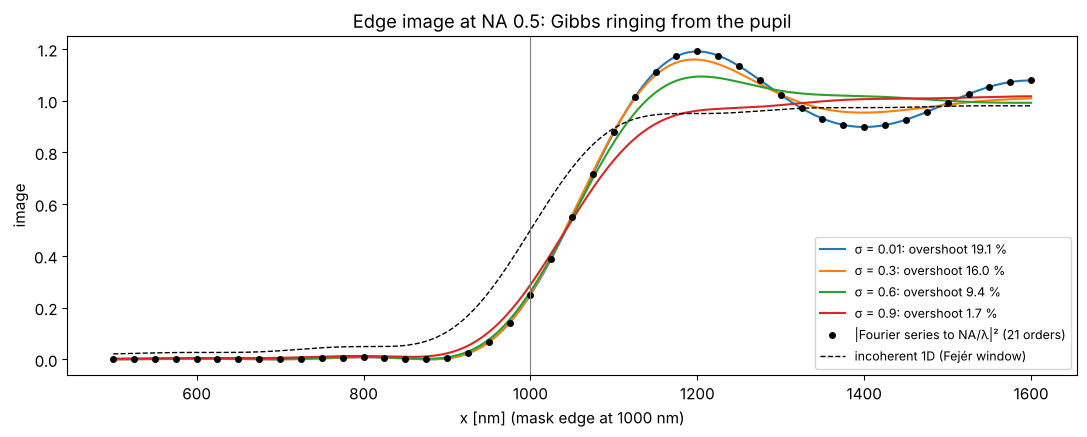

In [8]:
NA_d = 0.5
dry = Projector(NA_d, wl, 1.0, vectorial=False, obliquity=False)
edges = MaskLayout.lines_spaces(4000.0, 2000.0)
ue = np.linspace(500, 1600, 1101)
fig, ax = plt.subplots(figsize=(11, 4.5))
for k, s in enumerate((0.01, 0.3, 0.6, 0.9)):
    ill = Illumination.conventional(s, n_samples=3 if s < 0.05 else 31)
    I = np.ravel(LithoSimulation(edges, ThinMask.binary(), ill, dry).image(ue, None))
    ax.plot(ue, I, color=f"C{k}", lw=1.5, label=f"σ = {s:g}: overshoot {100*(I.max() - 1):.1f} %")
# coherent: |truncated Fourier series of the mask|^2
p_e = 4000.0
M_e = int(np.floor(p_e*NA_d/wl))
m = np.arange(-M_e, M_e + 1)
c_mask = np.where(m == 0, 0.5, -0.5*np.sinc(m/2))  # clear field, dark line of half the pitch at 0
E = np.real(np.exp(2j*np.pi*np.outer(ue, m)/p_e) @ c_mask)
ax.plot(ue[::25], E[::25]**2, "ko", ms=4, label=f"|Fourier series to NA/λ|² ({2*M_e + 1} orders)")
# incoherent, 1D: intensity series up to 2 NA/λ with the Fejer window
M_i = int(np.floor(p_e*2*NA_d/wl))
m_i = np.arange(-M_i, M_i + 1)
c_i = np.where(m_i == 0, 0.5, -0.5*np.sinc(m_i/2))*smoothing_window(m_i/(p_e*2*NA_d/wl), "fejer")
ax.plot(ue, np.real(np.exp(2j*np.pi*np.outer(ue, m_i)/p_e) @ c_i), "k--", lw=1,
        label="incoherent 1D (Fejér window)")
ax.axvline(1000, color="0.5", lw=0.8)
ax.set_xlabel("x [nm] (mask edge at 1000 nm)"); ax.set_ylabel("image")
ax.legend(fontsize=9, loc="lower right"); ax.set_title("Edge image at NA 0.5: Gibbs ringing from the pupil")
fig.tight_layout()

### 5c. Interpolate the image, then threshold

The resist threshold turns a band-limited image into a binary pattern. On
a grid, the printed region is a set of pixels and its width a multiple of
$\Delta x$; interpolating the *binary* pattern (with or without a window)
puts the edges between the pixels, rings, and cannot recover what the
threshold has thrown away. Interpolating the *aerial image* first and
thresholding the interpolant gives the exact edge between the samples.

Below: the 45 nm isolated line. Left: the CD through dose from the
thresholded image on a 5 nm grid (pixel count, and the 0.5 level of the
Fourier interpolated pixel pattern, plain and with sigma factors), and
from the threshold of the Fourier interpolated image on a 30 nm grid.
Right: both at one dose.

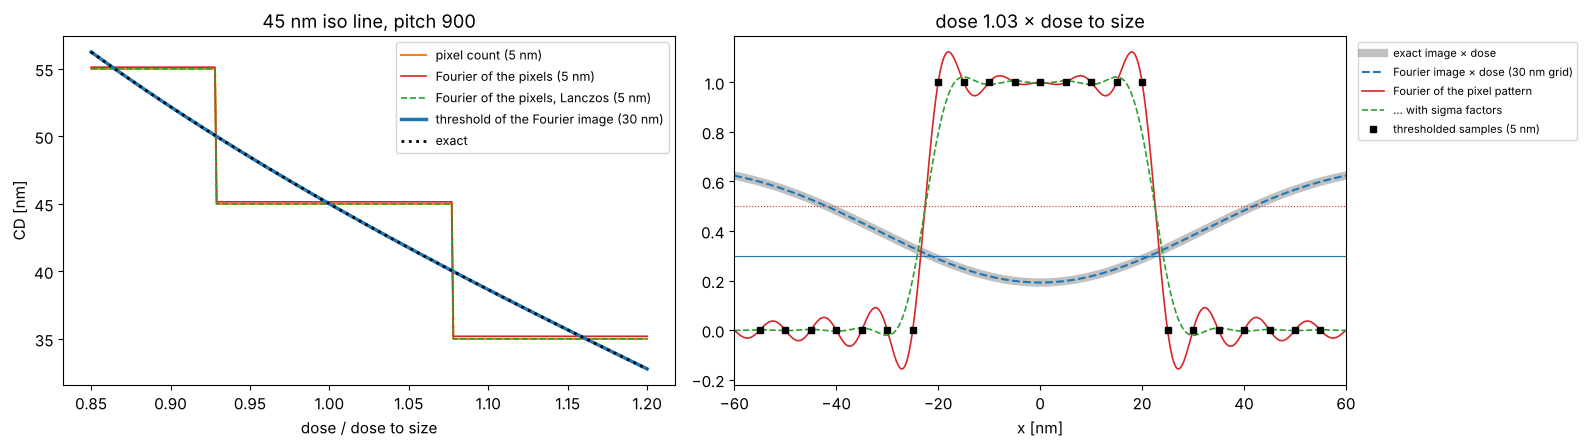

In [9]:
name = "45 nm iso line, pitch 900"
sim = cases[name]
p = sim.layout.pitch_x
u30, I30 = periodic_cut(sim, 30)    # 30 nm grid for the image
u5, I5 = periodic_cut(sim, 180)     # 5 nm grid for the pixel patterns
u_ref, I_ref = periodic_cut(sim, 100)
doses = np.linspace(0.85, 1.2, 351)*dose[name]


def pattern_cd(u, pattern, smoothing):
    # width of the remaining line (pattern = 1) at the 0.5 level of the interpolant
    c, rising = level_crossings(u, pattern, 0.5, smoothing=smoothing)
    c_rel = np.mod(c + p/2, p) - p/2  # relative to the line centre at 0
    left, right = c_rel[rising & (c_rel < 0)], c_rel[~rising & (c_rel > 0)]
    return right.min() - left.max() if len(left) and len(right) else np.nan


cds = {"pixel count (5 nm)": [], "Fourier of the pixels (5 nm)": [],
       "Fourier of the pixels, Lanczos (5 nm)": [], "threshold of the Fourier image (30 nm)": [],
       "exact": []}
for D in doses:
    line = (D*I5 < THRESHOLD).astype(float)  # 1 where the line remains
    cds["pixel count (5 nm)"].append(line.sum()*p/len(u5))
    cds["Fourier of the pixels (5 nm)"].append(pattern_cd(u5, line, None))
    cds["Fourier of the pixels, Lanczos (5 nm)"].append(pattern_cd(u5, line, "lanczos"))
    cds["threshold of the Fourier image (30 nm)"].append(fourier_cd(sim, u30, I30, D))
    cds["exact"].append(fourier_cd(sim, u_ref, I_ref, D))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
styles = {"pixel count (5 nm)": ("C1", "-", 1.5), "Fourier of the pixels (5 nm)": ("C3", "-", 1.2),
          "Fourier of the pixels, Lanczos (5 nm)": ("C2", "--", 1.2),
          "threshold of the Fourier image (30 nm)": ("C0", "-", 2.5), "exact": ("k", ":", 2)}
for key, v in cds.items():
    c, ls, lw = styles[key]
    axes[0].plot(doses/dose[name], v, color=c, ls=ls, lw=lw, label=key)
axes[0].set_xlabel("dose / dose to size"); axes[0].set_ylabel("CD [nm]")
axes[0].set_title(name); axes[0].legend(fontsize=9)

D = 1.03*dose[name]
uf = np.linspace(-60, 60, 961)
line = (D*I5 < THRESHOLD).astype(float)
ax = axes[1]
ax.plot(uf, D*np.ravel(sim.image(uf, None)), color="0.6", lw=6, alpha=0.6, label="exact image × dose")
ax.plot(uf, D*trig_interpolate(I30, u30, uf), "C0--", lw=1.5, label="Fourier image × dose (30 nm grid)")
ax.axhline(THRESHOLD, color="C0", lw=0.8)
ax.plot(uf, trig_interpolate(line, u5, uf), "C3", lw=1.2, label="Fourier of the pixel pattern")
ax.plot(uf, trig_interpolate(line, u5, uf, smoothing="lanczos"), "C2--", lw=1.2,
        label="… with sigma factors")
sel = np.abs(u5) < 60
ax.plot(u5[sel], line[sel], "ks", ms=4, label="thresholded samples (5 nm)")
ax.axhline(0.5, color="C3", lw=0.8, ls=":")
ax.set_xlabel("x [nm]"); ax.set_xlim(-60, 60)
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set_title(f"dose {D/dose[name]:.2f} × dose to size")
fig.tight_layout()

The pixel count of the 5 nm pattern jumps in steps of 10 nm (one pixel at
each edge of the symmetric line); interpolating the thresholded pattern only moves the
edges to the half-pixel positions, with or without the sigma factors, and
the steps stay. The threshold of the image interpolated from a six times
coarser grid follows the exact CD. Resist models with a smooth response keep most of this: a Gaussian
acid diffusion (`metrics.gaussian_blur()`) multiplies the spectrum by the
Gaussian window and leaves the image band limited, while a nonlinear
response such as the Dill exposure $1 - e^{-CDI}$ adds weak harmonics
beyond $2\,\mathrm{NA}/\lambda$: its Fourier interpolation converges fast but
is no longer exact.

## Summary

- The aerial image (in air, water or in the resist, any source, focus and
  aberrations) is band limited to $2\,\mathrm{NA}/\lambda$. A grid with
  $\Delta x \le \lambda/(4\,\mathrm{NA})$ (36 nm for NA 1.35 at 193 nm)
  carries it completely, and its trigonometric interpolation
  (`pyoptics.interpolator`) is the image everywhere between the samples.
- Threshold CDs from such a grid are exact with Fourier interpolation
  (`metrics.threshold_cd(..., interpolation="fourier")`); linear
  interpolation needs grids of a few nm for 0.1 nm accuracy, cubic splines
  10 to 20 nm. Below the Nyquist limit the image aliases and no interpolation
  helps.
- Data with edges (masks, thresholded resist, non-periodic cuts) are not band
  limited: Fourier interpolation rings (Gibbs, 9 to 14 % of the jump).
  Lanczos sigma factors reduce the overshoot to about 1 %, their square to
  0.2 %, the Fejér window removes it; all of them broaden the edge.
- The lens shows the same Gibbs ringing in coherent imaging (19 % in
  intensity at an edge); partial coherence acts as a smoothing window.
- For CDs: interpolate the image, then apply the threshold, never the other
  way round.

## References

- C. Lanczos, *Applied Analysis*, Prentice Hall (1956), ch. IV (sigma factors).
- J. P. Boyd, *Chebyshev and Fourier Spectral Methods*, 2nd ed., Dover (2001), ch. 2 and 11.
- D. Gottlieb and C.-W. Shu, "On the Gibbs phenomenon and its resolution", SIAM Review 39, 644–668 (1997).
- J. W. Goodman, *Introduction to Fourier Optics*, 3rd ed., Roberts (2005), ch. 6.
- C. Mack, *Fundamental Principles of Optical Lithography*, Wiley (2007), ch. 2 and 3.
- A. Erdmann, *Optical and EUV Lithography: A Modeling Perspective*, SPIE Press (2021).